<a href="https://colab.research.google.com/github/Sanika13112/DCGAN-CIFAR10_GenerativeAi/blob/main/DCGAN_CIFAR10_Sanika_Mane.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DCGAN on CIFAR-10 — Complete Assignment

**Aim:** Implement and train a Deep Convolutional Generative Adversarial Network (DCGAN), generate synthetic images, and evaluate Generator/Discriminator losses and visual quality.

This is a fresh experiment and does not depend on variables or weights from your earlier run. The deeper architecture and training setup are intended to help image quality, but no DCGAN setting guarantees perfect images.

**Colab:** Runtime → Change runtime type → T4 GPU (if available). Set `EPOCHS = 2` for a quick test; use 100 for the main experiment.

## 1. Import libraries and configure GPU

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load CIFAR-10 dataset
CIFAR-10 contains 60,000 colour images of size 32 × 32 × 3: 50,000 training images and 10,000 test images. This is an unconditional GAN, so class labels are not used for training.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step
Train: (50000, 32, 32, 3) Test: (10000, 32, 32, 3)


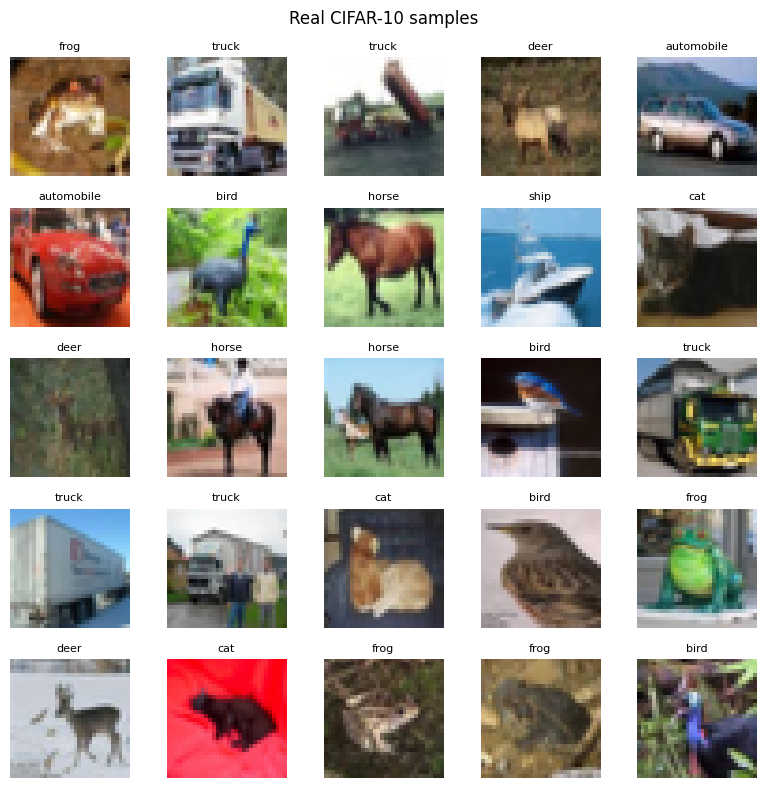

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("Train:", x_train.shape, "Test:", x_test.shape)

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])], fontsize=8)
    plt.axis("off")
plt.suptitle("Real CIFAR-10 samples")
plt.tight_layout()
plt.show()

## 3. Preprocess the images
Normalize pixel values from [0, 255] to [-1, 1], matching the Generator's `tanh` output.

In [ ]:
x_train = (x_train.astype("float32") - 127.5) / 127.5

BATCH_SIZE = 128
LATENT_DIM = 128

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(len(x_train), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)
print("Normalized range:", x_train.min(), "to", x_train.max())

Normalized range: -1.0 to 1.0


## 4. Build the Generator
The Generator maps a random 128-dimensional vector into a 32 × 32 RGB image. Transposed convolutions progressively upsample feature maps.

In [ ]:
def build_generator():
    model = tf.keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(LATENT_DIM,)))
    model.add(layers.Dense(4 * 4 * 512, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())
    model.add(layers.Reshape((4, 4, 512)))

    # 4x4 -> 8x8
    model.add(layers.Conv2DTranspose(256, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    # 8x8 -> 16x16
    model.add(layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    # 16x16 -> 32x32
    model.add(layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    model.add(layers.Conv2D(3, 3, padding="same", activation="tanh"))
    return model

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8192)           │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 256)      │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 3)      │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,837,379 (14.64 MB)

 Trainable params: 3,820,099 (14.57 MB)

 Non-trainable params: 17,280 (67.50 KB)

## 5. Build the Discriminator
The Discriminator uses strided convolution layers to extract image features and classify an image as real or generated. It outputs a raw logit; therefore, the loss uses `from_logits=True`.

In [ ]:
def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=(32, 32, 3)))

    model.add(layers.Conv2D(64, 4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(256, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(512, 4, strides=2, padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model

discriminator = build_discriminator()
discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 2, 2, 512)      │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 2, 2, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,761,281 (10.53 MB)

 Trainable params: 2,759,489 (10.53 MB)

 Non-trainable params: 1,792 (7.00 KB)

## 6. Loss functions and optimizers
The Discriminator learns to score real images as real and generated images as fake. The Generator learns to make generated images score as real. One-sided label smoothing uses 0.9 for real targets as a mild regularization technique.

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_logits, fake_logits):
    real_targets = tf.ones_like(real_logits) * 0.9
    fake_targets = tf.zeros_like(fake_logits)
    return (
        cross_entropy(real_targets, real_logits)
        + cross_entropy(fake_targets, fake_logits)
    )

def generator_loss(fake_logits):
    return cross_entropy(tf.ones_like(fake_logits), fake_logits)

LEARNING_RATE = 0.0002
generator_optimizer = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=0.5)

fixed_noise = tf.random.normal([25, LATENT_DIM])

## 7. Define the training step
Each batch first updates the Discriminator using real and fake images. It then updates the Generator to make the Discriminator classify newly generated images as real.

In [ ]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    # Update Discriminator.
    noise_d = tf.random.normal([batch_size, LATENT_DIM])
    with tf.GradientTape() as d_tape:
        fake_d = generator(noise_d, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(tf.stop_gradient(fake_d), training=True)
        d_loss = discriminator_loss(real_logits, fake_logits)

    d_gradients = d_tape.gradient(d_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # Update Generator.
    noise_g = tf.random.normal([batch_size, LATENT_DIM])
    with tf.GradientTape() as g_tape:
        fake_g = generator(noise_g, training=True)
        fake_logits_for_g = discriminator(fake_g, training=True)
        g_loss = generator_loss(fake_logits_for_g)

    g_gradients = g_tape.gradient(g_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )
    return g_loss, d_loss

## 8. Configure training and checkpointing
This notebook starts a fresh run. It saves model/optimizer state every five epochs so training can be resumed after a Colab disconnect. For a fresh experiment, leave `RESUME_FROM_CHECKPOINT = False`.

In [ ]:
EPOCHS = 100
RESUME_FROM_CHECKPOINT = False

os.makedirs("dcgan_outputs", exist_ok=True)
os.makedirs("dcgan_checkpoints", exist_ok=True)

generator_losses = []
discriminator_losses = []

def generate_and_save_images(model, epoch, noise):
    images = model(noise, training=False)
    images = (images + 1.0) / 2.0

    plt.figure(figsize=(7, 7))
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(tf.clip_by_value(images[i], 0.0, 1.0))
        plt.axis("off")
    plt.suptitle(f"Generated images — Epoch {epoch}")
    plt.tight_layout()
    plt.savefig(f"dcgan_outputs/generated_epoch_{epoch:03d}.png", dpi=160)
    plt.show()
    plt.close()

completed_epoch = tf.Variable(0, dtype=tf.int64, trainable=False)
checkpoint = tf.train.Checkpoint(
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer,
    completed_epoch=completed_epoch
)
manager = tf.train.CheckpointManager(checkpoint, "dcgan_checkpoints", max_to_keep=3)

if RESUME_FROM_CHECKPOINT and manager.latest_checkpoint:
    checkpoint.restore(manager.latest_checkpoint).expect_partial()
    start_epoch = int(completed_epoch.numpy()) + 1
    if os.path.exists("dcgan_training_history.npz"):
        h = np.load("dcgan_training_history.npz")
        generator_losses = h["generator_losses"].tolist()
        discriminator_losses = h["discriminator_losses"].tolist()
    print("Restored. Continuing from epoch", start_epoch)
else:
    start_epoch = 1
    print("Fresh training run.")

Fresh training run.


## 9. Train the DCGAN
Default: 100 epochs. Use a GPU. The first epoch may take longer because TensorFlow traces the training function.

Epoch 001/100 | Generator loss: 3.9886 | Discriminator loss: 0.8917


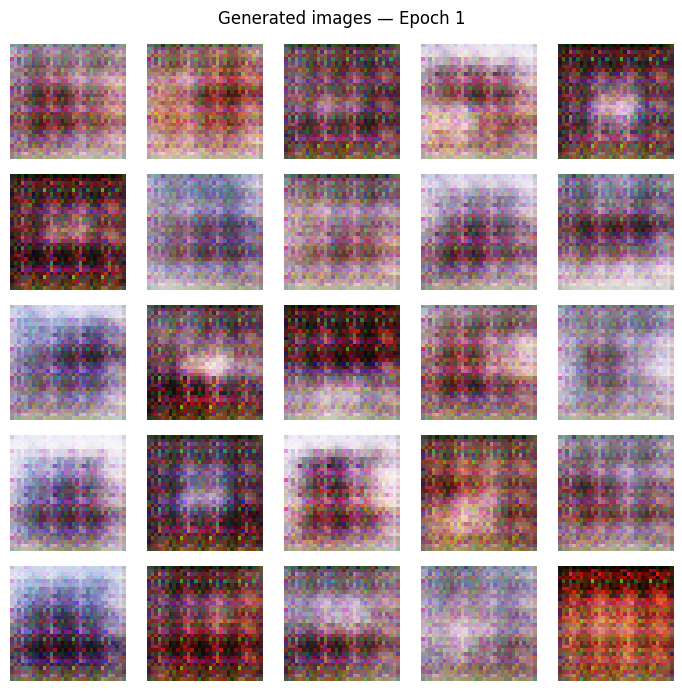

Epoch 002/100 | Generator loss: 2.3208 | Discriminator loss: 1.0766
Epoch 003/100 | Generator loss: 2.6665 | Discriminator loss: 0.9582
Epoch 004/100 | Generator loss: 3.0081 | Discriminator loss: 0.9035
Epoch 005/100 | Generator loss: 2.6528 | Discriminator loss: 0.9858
Epoch 006/100 | Generator loss: 2.3956 | Discriminator loss: 0.9781
Epoch 007/100 | Generator loss: 2.2464 | Discriminator loss: 1.0100
Epoch 008/100 | Generator loss: 2.1117 | Discriminator loss: 1.0079
Epoch 009/100 | Generator loss: 2.0445 | Discriminator loss: 1.0653
Epoch 010/100 | Generator loss: 1.9495 | Discriminator loss: 1.0822


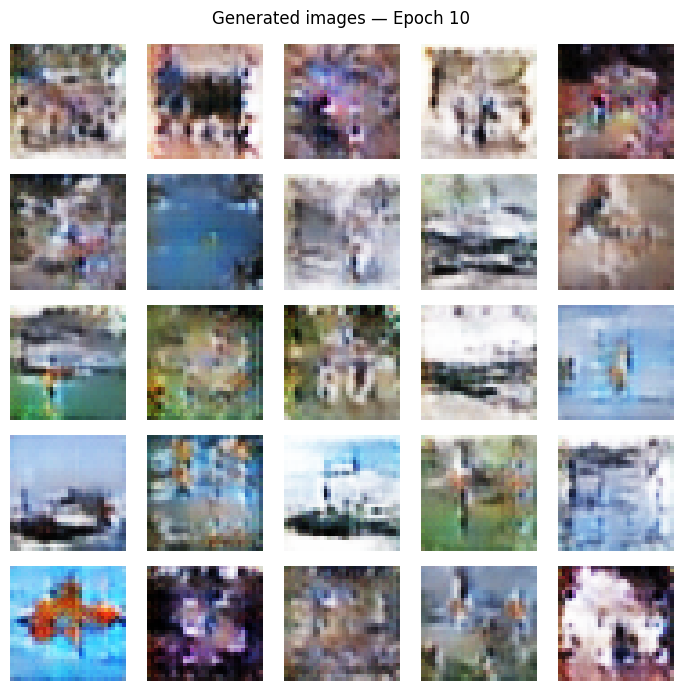

Epoch 011/100 | Generator loss: 1.9655 | Discriminator loss: 1.0487
Epoch 012/100 | Generator loss: 1.9596 | Discriminator loss: 1.0341
Epoch 013/100 | Generator loss: 1.9486 | Discriminator loss: 1.0124
Epoch 014/100 | Generator loss: 1.9391 | Discriminator loss: 1.0115
Epoch 015/100 | Generator loss: 1.9536 | Discriminator loss: 0.9932
Epoch 016/100 | Generator loss: 1.8230 | Discriminator loss: 1.0027
Epoch 017/100 | Generator loss: 1.9017 | Discriminator loss: 0.9602
Epoch 018/100 | Generator loss: 1.8961 | Discriminator loss: 0.9871
Epoch 019/100 | Generator loss: 1.9290 | Discriminator loss: 0.9543
Epoch 020/100 | Generator loss: 1.8198 | Discriminator loss: 1.0079


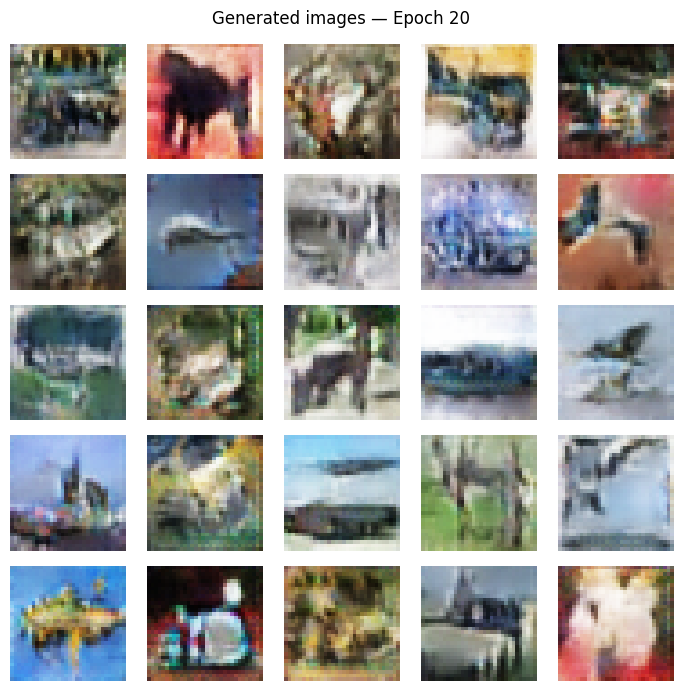

Epoch 021/100 | Generator loss: 1.7751 | Discriminator loss: 1.0069
Epoch 022/100 | Generator loss: 1.7513 | Discriminator loss: 0.9768
Epoch 023/100 | Generator loss: 1.7656 | Discriminator loss: 0.9733
Epoch 024/100 | Generator loss: 1.7615 | Discriminator loss: 0.9927
Epoch 025/100 | Generator loss: 1.7927 | Discriminator loss: 0.9671
Epoch 026/100 | Generator loss: 1.8132 | Discriminator loss: 0.9668
Epoch 027/100 | Generator loss: 1.8046 | Discriminator loss: 0.9707
Epoch 028/100 | Generator loss: 1.7862 | Discriminator loss: 0.9485
Epoch 029/100 | Generator loss: 1.7854 | Discriminator loss: 0.9528
Epoch 030/100 | Generator loss: 1.7891 | Discriminator loss: 0.9553


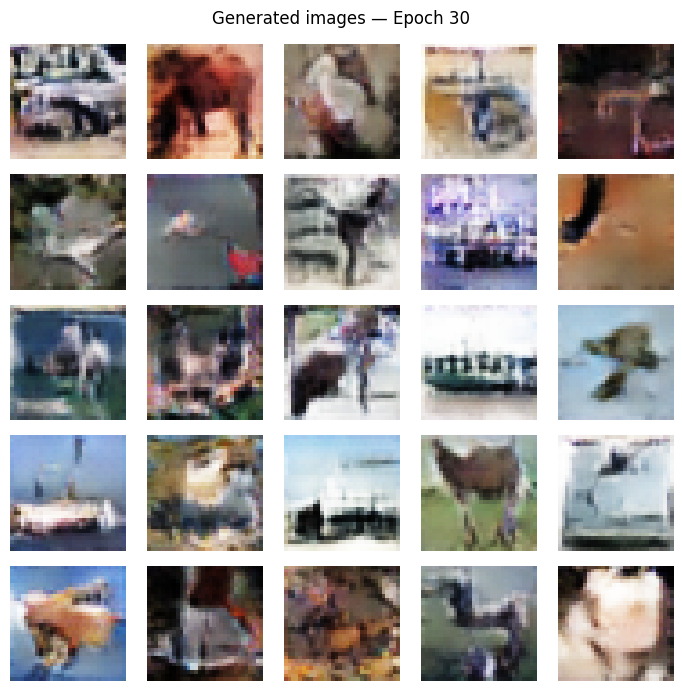

Epoch 031/100 | Generator loss: 1.8225 | Discriminator loss: 0.9406
Epoch 032/100 | Generator loss: 1.8329 | Discriminator loss: 0.9237
Epoch 033/100 | Generator loss: 1.8473 | Discriminator loss: 0.9582
Epoch 034/100 | Generator loss: 1.8165 | Discriminator loss: 0.9302
Epoch 035/100 | Generator loss: 1.8884 | Discriminator loss: 0.9277
Epoch 036/100 | Generator loss: 1.8619 | Discriminator loss: 0.9400
Epoch 037/100 | Generator loss: 1.8525 | Discriminator loss: 0.9100
Epoch 038/100 | Generator loss: 1.8428 | Discriminator loss: 0.9225
Epoch 039/100 | Generator loss: 1.8643 | Discriminator loss: 0.8809
Epoch 040/100 | Generator loss: 1.9314 | Discriminator loss: 0.8843


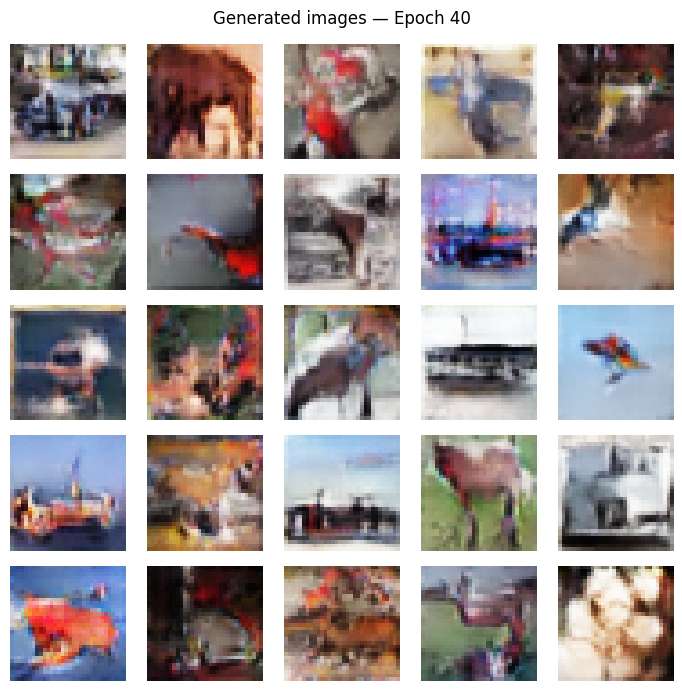

Epoch 041/100 | Generator loss: 2.2212 | Discriminator loss: 0.8538
Epoch 042/100 | Generator loss: 1.9204 | Discriminator loss: 0.8887
Epoch 043/100 | Generator loss: 1.9009 | Discriminator loss: 0.8679
Epoch 044/100 | Generator loss: 1.9683 | Discriminator loss: 0.8915
Epoch 045/100 | Generator loss: 1.9622 | Discriminator loss: 0.8780
Epoch 046/100 | Generator loss: 1.9657 | Discriminator loss: 0.8690
Epoch 047/100 | Generator loss: 2.0857 | Discriminator loss: 0.8328
Epoch 048/100 | Generator loss: 2.1173 | Discriminator loss: 0.8417
Epoch 049/100 | Generator loss: 1.9958 | Discriminator loss: 0.8474
Epoch 050/100 | Generator loss: 1.9922 | Discriminator loss: 0.8810


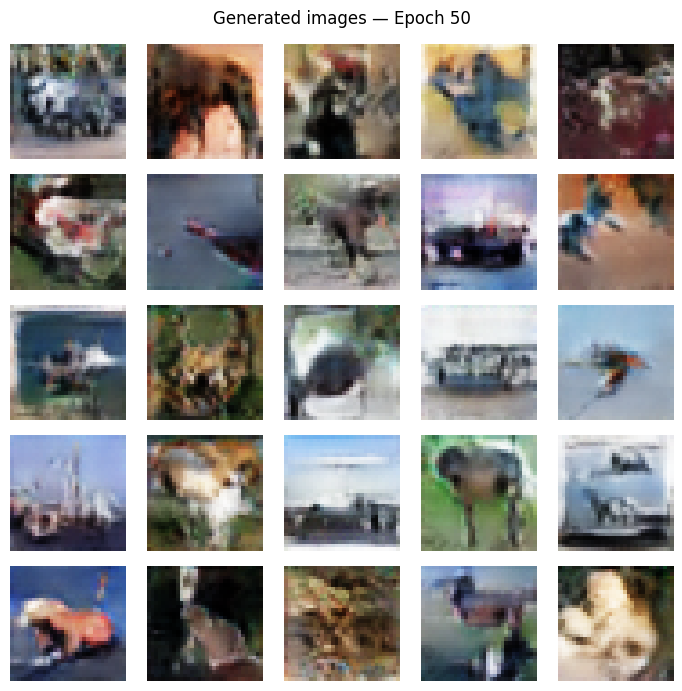

Epoch 051/100 | Generator loss: 1.9562 | Discriminator loss: 0.8833
Epoch 052/100 | Generator loss: 2.0022 | Discriminator loss: 0.8628
Epoch 053/100 | Generator loss: 1.9748 | Discriminator loss: 0.8462
Epoch 054/100 | Generator loss: 2.0707 | Discriminator loss: 0.8339
Epoch 055/100 | Generator loss: 2.0451 | Discriminator loss: 0.8481
Epoch 056/100 | Generator loss: 2.0398 | Discriminator loss: 0.8603
Epoch 057/100 | Generator loss: 2.0805 | Discriminator loss: 0.8107
Epoch 058/100 | Generator loss: 2.0975 | Discriminator loss: 0.8208
Epoch 059/100 | Generator loss: 2.0997 | Discriminator loss: 0.8336
Epoch 060/100 | Generator loss: 2.0966 | Discriminator loss: 0.8228


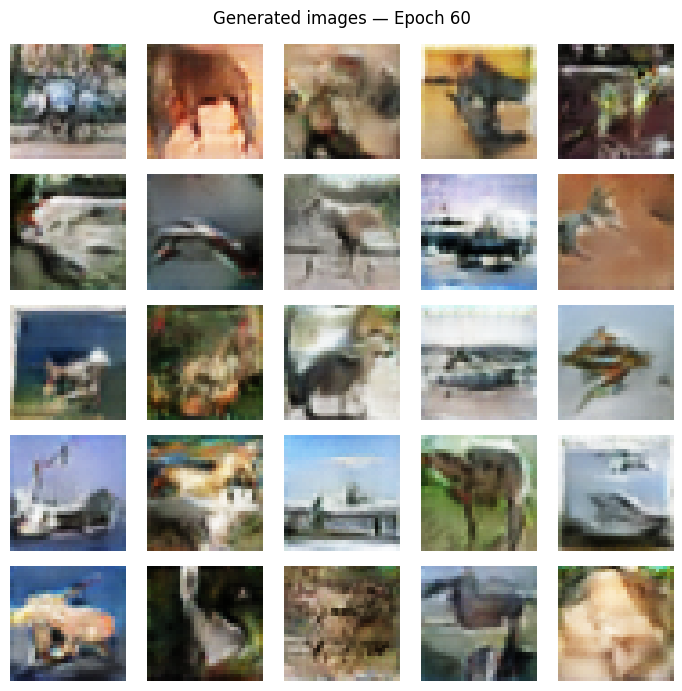

Epoch 061/100 | Generator loss: 2.1228 | Discriminator loss: 0.8138
Epoch 062/100 | Generator loss: 2.1326 | Discriminator loss: 0.8116
Epoch 063/100 | Generator loss: 2.0963 | Discriminator loss: 0.8150
Epoch 064/100 | Generator loss: 2.1493 | Discriminator loss: 0.8134
Epoch 065/100 | Generator loss: 2.1001 | Discriminator loss: 0.8130
Epoch 066/100 | Generator loss: 2.1774 | Discriminator loss: 0.7956
Epoch 067/100 | Generator loss: 2.1826 | Discriminator loss: 0.7916
Epoch 068/100 | Generator loss: 2.1466 | Discriminator loss: 0.7993
Epoch 069/100 | Generator loss: 2.1363 | Discriminator loss: 0.8063
Epoch 070/100 | Generator loss: 2.1854 | Discriminator loss: 0.8049


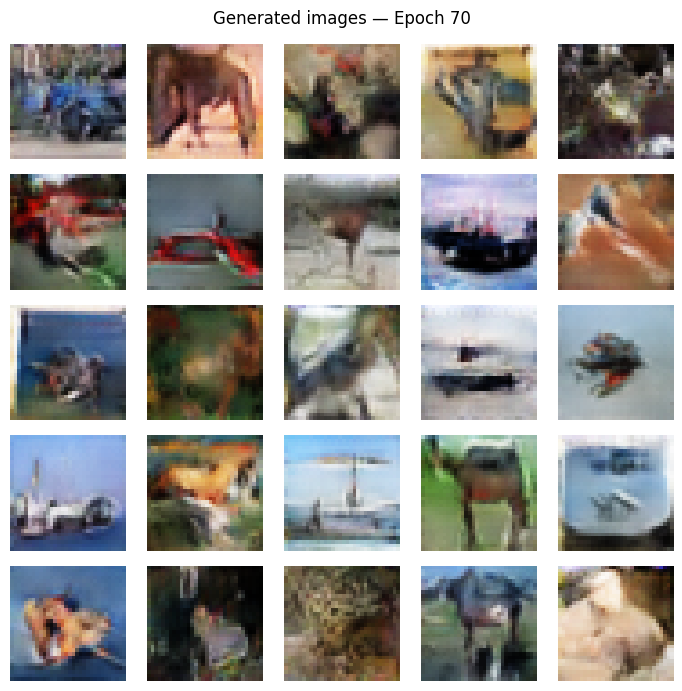

Epoch 071/100 | Generator loss: 2.1513 | Discriminator loss: 0.7791
Epoch 072/100 | Generator loss: 2.1681 | Discriminator loss: 0.7819
Epoch 073/100 | Generator loss: 2.2360 | Discriminator loss: 0.8024
Epoch 074/100 | Generator loss: 2.2331 | Discriminator loss: 0.7620
Epoch 075/100 | Generator loss: 2.2639 | Discriminator loss: 0.7764
Epoch 076/100 | Generator loss: 2.2031 | Discriminator loss: 0.7868
Epoch 077/100 | Generator loss: 2.2671 | Discriminator loss: 0.7673
Epoch 078/100 | Generator loss: 2.2852 | Discriminator loss: 0.7720
Epoch 079/100 | Generator loss: 2.2896 | Discriminator loss: 0.7711
Epoch 080/100 | Generator loss: 2.2169 | Discriminator loss: 0.7537


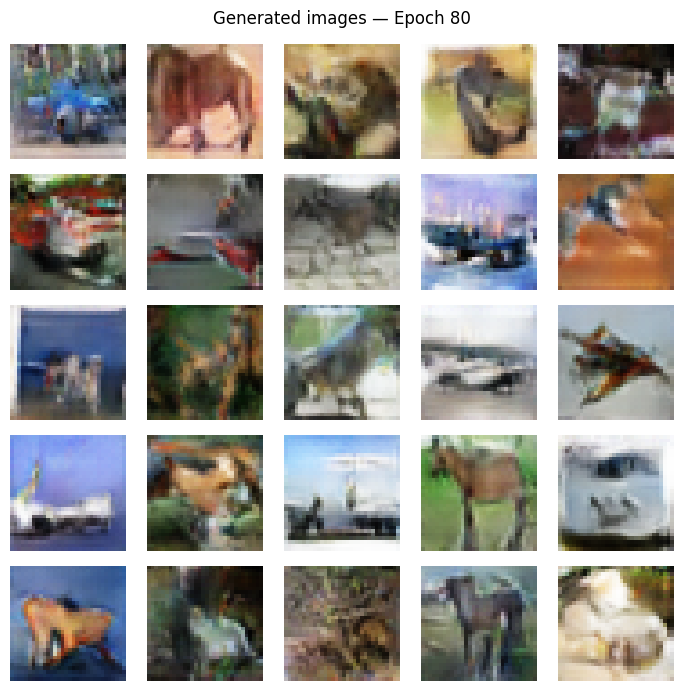

Epoch 081/100 | Generator loss: 2.2814 | Discriminator loss: 0.7797
Epoch 082/100 | Generator loss: 2.2856 | Discriminator loss: 0.7427
Epoch 083/100 | Generator loss: 2.2984 | Discriminator loss: 0.7773
Epoch 084/100 | Generator loss: 2.2871 | Discriminator loss: 0.7556
Epoch 085/100 | Generator loss: 2.3025 | Discriminator loss: 0.7488
Epoch 086/100 | Generator loss: 2.3412 | Discriminator loss: 0.7408
Epoch 087/100 | Generator loss: 2.3240 | Discriminator loss: 0.7512
Epoch 088/100 | Generator loss: 2.3647 | Discriminator loss: 0.7700
Epoch 089/100 | Generator loss: 2.3317 | Discriminator loss: 0.7474
Epoch 090/100 | Generator loss: 2.4012 | Discriminator loss: 0.7449


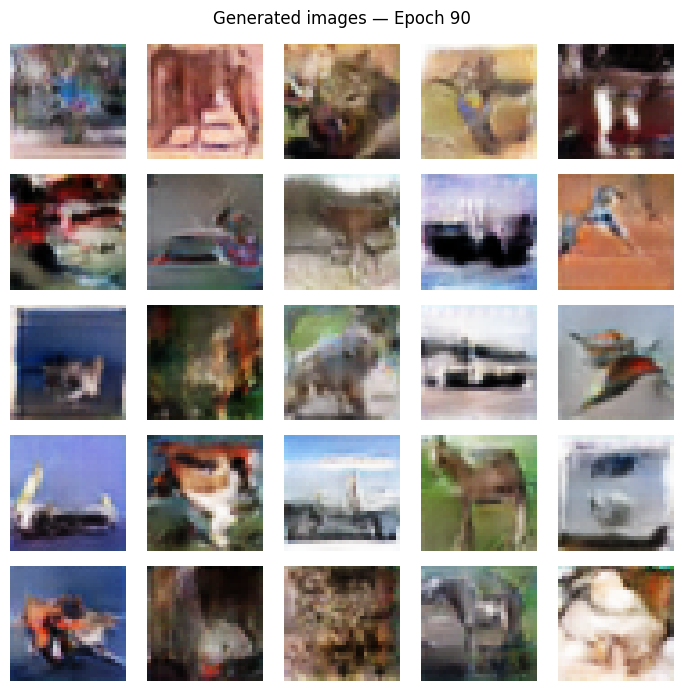

Epoch 091/100 | Generator loss: 2.3746 | Discriminator loss: 0.7415
Epoch 092/100 | Generator loss: 2.4233 | Discriminator loss: 0.7279
Epoch 093/100 | Generator loss: 2.3477 | Discriminator loss: 0.7346
Epoch 094/100 | Generator loss: 2.3215 | Discriminator loss: 0.7490
Epoch 095/100 | Generator loss: 2.3897 | Discriminator loss: 0.7168
Epoch 096/100 | Generator loss: 2.4261 | Discriminator loss: 0.7306
Epoch 097/100 | Generator loss: 2.3859 | Discriminator loss: 0.7225
Epoch 098/100 | Generator loss: 2.3910 | Discriminator loss: 0.7323
Epoch 099/100 | Generator loss: 2.3965 | Discriminator loss: 0.7440
Epoch 100/100 | Generator loss: 2.4163 | Discriminator loss: 0.7174


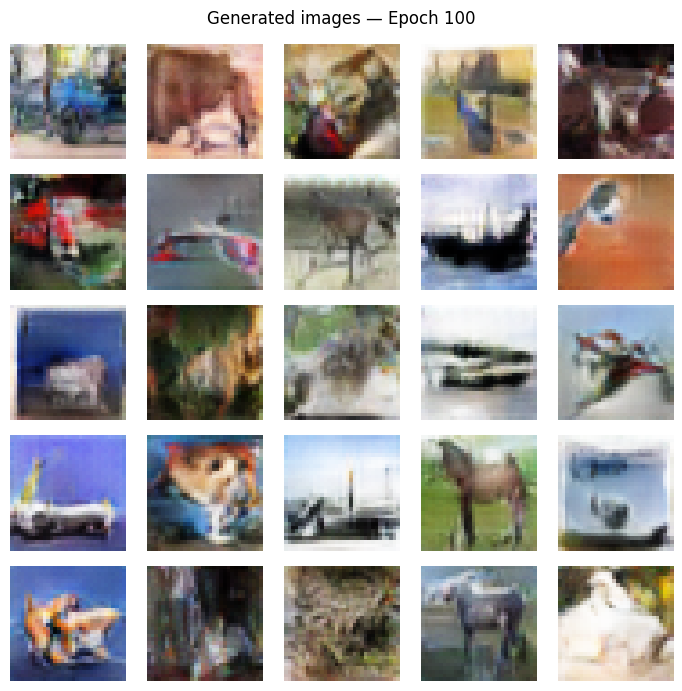

Training completed.


In [ ]:
for epoch in range(start_epoch, EPOCHS + 1):
    g_metric = tf.keras.metrics.Mean()
    d_metric = tf.keras.metrics.Mean()

    for real_batch in train_dataset:
        g_loss, d_loss = train_step(real_batch)
        g_metric.update_state(g_loss)
        d_metric.update_state(d_loss)

    g_value = float(g_metric.result().numpy())
    d_value = float(d_metric.result().numpy())
    generator_losses.append(g_value)
    discriminator_losses.append(d_value)
    completed_epoch.assign(epoch)

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Generator loss: {g_value:.4f} | "
        f"Discriminator loss: {d_value:.4f}"
    )

    if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS:
        generate_and_save_images(generator, epoch, fixed_noise)

    if epoch % 5 == 0 or epoch == EPOCHS:
        manager.save()
        np.savez(
            "dcgan_training_history.npz",
            generator_losses=np.array(generator_losses),
            discriminator_losses=np.array(discriminator_losses)
        )

print("Training completed.")

## 10. Plot the loss curves
GAN losses can fluctuate. Do not judge image quality using loss alone; inspect generated samples as well.

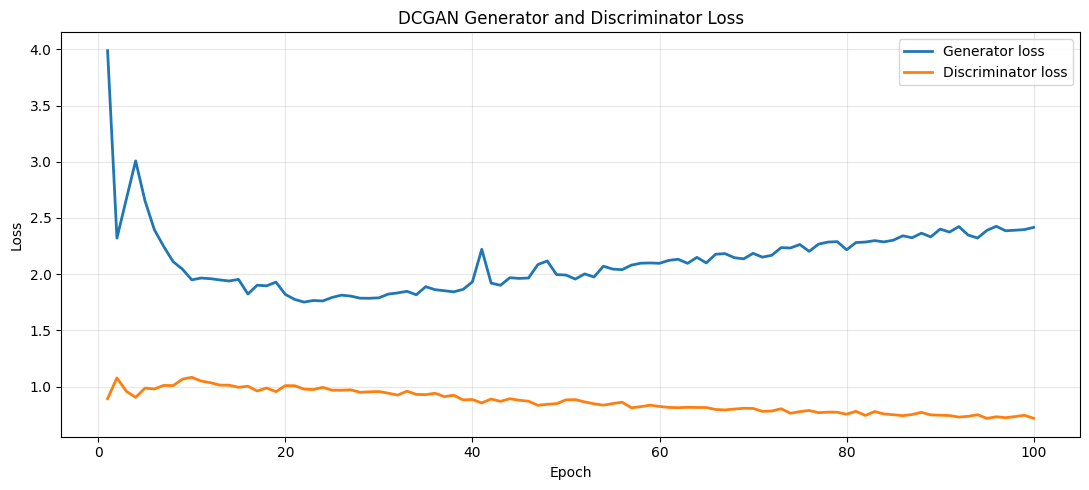

Epochs recorded: 100
Final Generator loss: 2.4163
Final Discriminator loss: 0.7174


In [ ]:
epochs_done = len(generator_losses)
epoch_axis = range(1, epochs_done + 1)

plt.figure(figsize=(11, 5))
plt.plot(epoch_axis, generator_losses, label="Generator loss", linewidth=2)
plt.plot(epoch_axis, discriminator_losses, label="Discriminator loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Generator and Discriminator Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("dcgan_loss_curves.png", dpi=160)
plt.show()

print("Epochs recorded:", epochs_done)
print("Final Generator loss:", round(generator_losses[-1], 4))
print("Final Discriminator loss:", round(discriminator_losses[-1], 4))

## 11. Generate final synthetic images

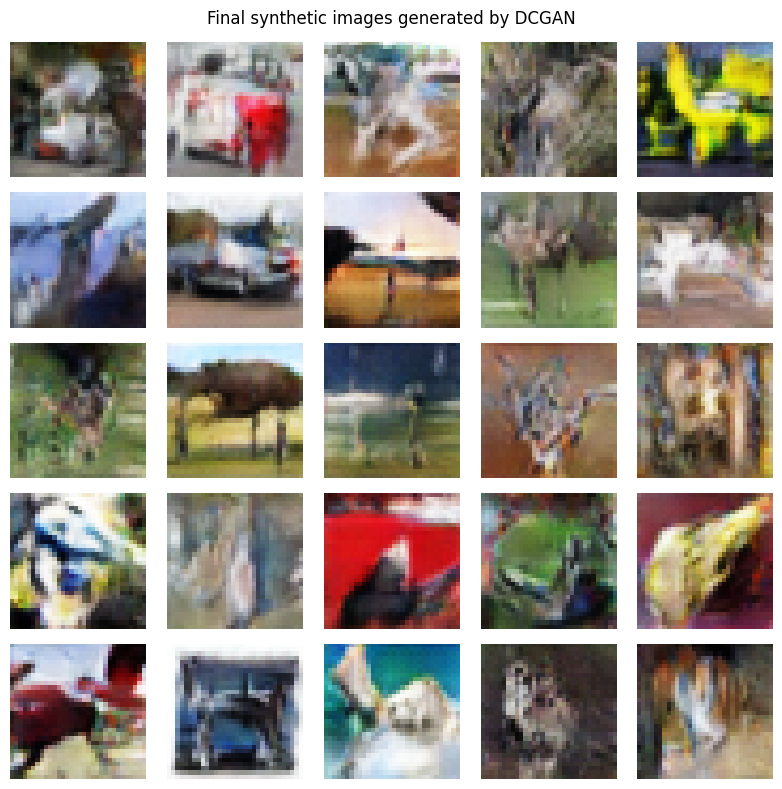

In [ ]:
# New random noise creates a fresh set of 25 synthetic images.
new_noise = tf.random.normal([25, LATENT_DIM])
final_images = generator(new_noise, training=False)
final_images = (final_images + 1.0) / 2.0

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(tf.clip_by_value(final_images[i], 0.0, 1.0))
    plt.axis("off")
plt.suptitle("Final synthetic images generated by DCGAN")
plt.tight_layout()
plt.savefig("dcgan_final_generated_images.png", dpi=160)
plt.show()

## 12. Save trained models and outputs

In [ ]:
generator.save("dcgan_generator.keras")
discriminator.save("dcgan_discriminator.keras")

np.savez(
    "dcgan_training_history.npz",
    generator_losses=np.array(generator_losses),
    discriminator_losses=np.array(discriminator_losses)
)

print("Saved Generator, Discriminator, loss history and generated images.")

Saved Generator, Discriminator, loss history and generated images.


## 13. Performance evaluation

Complete these observations after running the notebook. Use the actual graph and generated images rather than inventing results.

| Evaluation | What to inspect |
|---|---|
| Generator loss | Trend and fluctuations across epochs |
| Discriminator loss | Trend and balance with Generator |
| Image clarity | Recognizable shapes, colours and fewer artifacts |
| Image diversity | Whether samples are varied or repetitive |
| Training stability | Compare generated grids at different checkpoints |

### Observation template

Observations

1. Generator loss trend: The Generator loss initially decreased from approximately 4.0 to 1.75, but gradually increased towards 2.4 in later epochs, indicating difficulty in fooling the Discriminator.

2. Discriminator loss trend: The Discriminator loss initially fluctuated but gradually decreased to approximately 0.7, indicating that it became better at distinguishing real and generated images.

3. Generated image quality: The generated images showed recognizable patterns, colours and rough structures resembling objects such as animals, vehicles and ships. However, some images remained blurry and distorted.

4. Image diversity: The Generator produced different images with variations in colours, shapes and textures. No obvious complete mode collapse was observed.

5. Overall performance: The DCGAN successfully learned basic visual patterns from the CIFAR-10 dataset and generated synthetic images. However, the increasing Generator loss and decreasing Discriminator loss indicate an imbalance in adversarial training. Further optimization is required to improve image clarity and training stability.

Final result: The DCGAN was successfully implemented and trained for 100 epochs. Synthetic images were generated, and model performance was evaluated using loss curves and visual inspection.
**Limitations:** CIFAR-10 images are only 32 × 32 pixels. A basic DCGAN may still produce blurry or abstract images. More epochs do not always improve results. Loss curves alone do not measure image realism; this notebook uses loss analysis and visual inspection and does not calculate FID or Inception Score.

## 14. Result

A DCGAN was implemented using TensorFlow/Keras and trained on CIFAR-10. The Generator produced 32 × 32 RGB synthetic images from random latent vectors, while the Discriminator learned to distinguish real images from generated images. Loss curves and generated samples were produced to evaluate the training process.

## 15. Conclusion

This experiment demonstrates adversarial image generation using a Deep Convolutional Generative Adversarial Network. The Generator and Discriminator learn through a competitive training process. Loss curves help analyze training behaviour, while generated image grids provide a visual assessment of the learned patterns. The experiment also demonstrates that GAN training can fluctuate and that image quality depends on architecture, training stability, data complexity and available computation.